# Практическая работа №1: Основы анализа и моделирования социальных сетей

Выполнил студент гр. 4385 Юферев Артём Сергеевич. Вариант №11.

## Цель работы

Овладеть навыками работы с математическими пакетами для моделирования, визуализации и анализа социальных сетей

## Основные теоретические положения

**Социальная сеть** — это структура, состоящая из множества акторов (вершин) и связей между ними (рёбер). Формально задаётся графом $G = (V, E)$, где $V$ — множество вершин, $E$ — множество рёбер.

**Социоматрица** (матрица смежности) — квадратная матрица $A$ размера $N \times N$, где $N = |V|$. Элемент $a_{ij} = 1$, если между вершинами $i$ и $j$ существует связь, и $a_{ij} = 0$ в противном случае.

**Размер сети** определяется числом вершин $N$ и числом рёбер $E$.

**Плотность сети** — отношение числа существующих рёбер к максимально возможному их числу. Для ненаправленного графа:
$$D = \frac{2E}{N(N-1)}$$
Для направленного графа:
$$D = \frac{E}{N(N-1)}$$

**Компонента связности** — максимальное подмножество вершин, в котором любые две вершины достижимы друг из друга. Для направленных графов различают **слабую** связность (при игнорировании направления рёбер) и **сильную** (с учётом направления).

**Диаметр сети** — максимальное кратчайшее расстояние между двумя вершинами:
$$\mathrm{diam}(G) = \max_{u,v \in V} d(u,v)$$
где $d(u,v)$ — длина кратчайшего пути между вершинами $u$ и $v$.

**Коэффициент кластеризации** вершины $i$ показывает, насколько связаны между собой её соседи:
$$C_i = \frac{2 t_i}{k_i(k_i-1)}$$
где $t_i$ — число треугольников, проходящих через вершину $i$, $k_i$ — её степень. Глобальный коэффициент кластеризации — отношение числа треугольников к числу связных троек вершин.

**Меры центральности** (для ненаправленных сетей):
- Степенная центральность: $C_D(i) = \frac{k_i}{N-1}$;
- Посредническая центральность: $C_B(i) = \sum_{s \neq i \neq t} \frac{\sigma_{st}(i)}{\sigma_{st}}$, где $\sigma_{st}$ — число кратчайших путей между $s$ и $t$, $\sigma_{st}(i)$ — число таких путей, проходящих через $i$;
- Близостная центральность: $C_I(i) = \frac{N-1}{\sum_{j} d(i,j)}$.

**Меры престижа** (для направленных сетей, учитывают входящие связи):
- Степень престижа: $P_D(i) = \frac{k_i^{\mathrm{in}}}{N-1}$;
- Близость престижа: $P_P(i)$ — близостная центральность, рассчитанная по входящим путям;
- Ранг престижа (PageRank): $P_R(i)$ — вероятность попадания в вершину $i$ при случайном блуждании по направленным связям, где на каждом шаге с вероятностью $d$ происходит переход по случайной исходящей связи, а с вероятностью $1-d$ — равномерный переход в любую вершину.


## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей вычислить описательные характеристики. Полученные результаты содержательно проинтерпретировать.


## Выполнение работы

### Ненаправленная сеть

**Первый пункт. Извлечение социоматрицы из файла florentine_business.csv и вывод на экран**

In [ ]:
library(igraph)

data <- read.csv("florentine_business.csv",
                comment.char = "#",
                header = TRUE)

rownames(data) <- colnames(data)
print(data)

**Второй пункт. Преобразование социоматрицы в список рёбер и вывод первых 5 рёбер**

In [ ]:
g <- graph_from_adjacency_matrix(as.matrix(data))

head(as_edgelist(g), 5)

**Третий пункт. Присвоение имён столбцам и строкам социоматрицы**

In [ ]:
colnames(data)
rownames(data)

**Четвёртый пункт. Построение ненаправленной сети и объяснение параметров функции**

Параметры функции graph_from_adjacency_matrix:
- as.matrix(data) - преобразует data в матрицу;
- mode = "undirected" - указывает, что граф будет ненаправленным;
- weighted = NULL - указывает, что граф не будет взвешенным;
- diag = FALSE - указывает, что диагональные элементы матрицы не будут использоваться для построения графа.

In [ ]:
g <- graph_from_adjacency_matrix(as.matrix(data),
                                 mode = "undirected",
                                 weighted = NULL,
                                 diag = FALSE)

g

**Пятый пункт. Отображение сети алгоритмами укладки Fruchterman-Reingold и Kamada-Kawai**

Фрюхтерман-Рейнгольд — это алгоритм укладки, использующий физическую модель, где вершины отталкиваются друг от друга, а рёбра притягивают связанные вершины. Алгоритм обеспечивает равномерное распределение вершин.

Камада-Каваи — алгоритм укладки, рассчитывающий оптимальное расположение вершин на основе расстояний между ними, пропорциональных к длине рёбер.

In [ ]:
par(mfrow = c(1, 2), mar = c(0, 0, 1, 0))

plot(g, layout = layout_with_fr(g), main = "Fruchterman-Reingold")
plot(g, layout = layout_with_kk(g), main = "Kamada-Kawai")

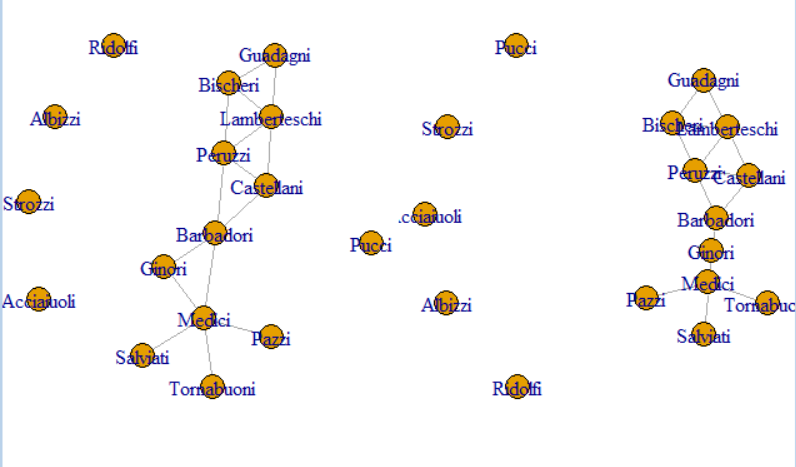

**Шестой пункт. Вывод сводной информации о сети**

In [ ]:
summary(g)

**Седьмой пункт. Пятичисловая сводка сети**

In [ ]:
N <- vcount(g)
E <- ecount(g)

density <- 2*E/(N*(N-1))
density
edge_density(g)

components <- components(g)
components$no

diameter <- diameter(g)
diameter

transitivity(g, type = "global")
transitivity(g, type = "average")

**Восьмой пункт. Таблица мер центральности для всех вершин сети**

In [ ]:
g_sub <- induced_subgraph(g, which(degree(g) > 0))
CD <- degree(g_sub, normalized = TRUE)
CB <- betweenness(g_sub, directed = FALSE, normalized = TRUE)
CI <- closeness(g_sub, normalized = TRUE)
centrality_table <- data.frame(ni = V(g_sub)$name, CD, CB, CI)
print(centrality_table)

| ni           | CD  | CB                 | CI                |
|--------------|-----|--------------------|-------------------|
| Barbadori    | 0.4 | 0.555555555555556  | 0.588235294117647 |
| Bischeri     | 0.3 | 0.0555555555555556 | 0.4               |
| Castellani   | 0.3 | 0.111111111111111  | 0.5               |
| Ginori       | 0.2 | 0                  | 0.454545454545455 |
| Guadagni     | 0.2 | 0                  | 0.3125            |
| Lamberteschi | 0.4 | 0.133333333333333  | 0.416666666666667 |
| Medici       | 0.5 | 0.533333333333333  | 0.526315789473684 |
| Pazzi        | 0.1 | 0                  | 0.357142857142857 |
| Peruzzi      | 0.4 | 0.3                | 0.526315789473684 |
| Salviati     | 0.1 | 0                  | 0.357142857142857 |
| Tornabuoni   | 0.1 | 0                  | 0.357142857142857 |



### Направленная сеть

**Девятый пункт. Выполнение пунктов 2-7 для направленной сети**

In [ ]:
data_dir <- read.csv("krackhardt_advice.csv",
                     comment.char = "#",
                     header = FALSE)

rownames(data_dir) <- colnames(data_dir)
n <- nrow(data_dir)
print(data_dir)

In [ ]:
g_dir <- graph_from_adjacency_matrix(as.matrix(data_dir),
                                     mode = "directed", 
                                     weighted = NULL, 
                                     diag = FALSE)

head(as_edgelist(g_dir), 5)

colnames(data_dir)
rownames(data_dir)

g_dir

par(mfrow = c(1, 2), mar = c(0, 0, 1, 0))
plot(g_dir, layout = layout_with_fr(g_dir), main = "Fruchterman-Reingold")
plot(g_dir, layout = layout_with_kk(g_dir), main = "Kamada-Kawai")

summary(g_dir)

N_dir <- vcount(g_dir)
E_dir <- ecount(g_dir)

density_dir <- E_dir / (N_dir * (N_dir - 1))
density_dir
edge_density(g_dir)

components_dir <- components(g_dir)
components_dir$no

diameter(g_dir, directed = TRUE)

transitivity(g_dir, type = "global")
transitivity(g_dir, type = "average")

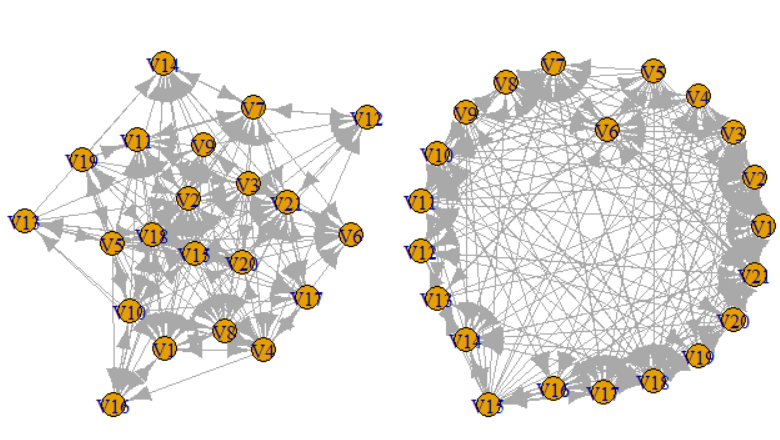

**Десятый пункт. Таблица мер престижа для направленной сети**

In [ ]:
PD <- degree(g_dir, mode = "in", normalized = TRUE)
PP <- closeness(g_dir, mode = "in", normalized = TRUE)
PR <- page_rank(g_dir)$vector

prestige_table <- data.frame(ni = V(g_dir)$name, PD, PP, PR)
print(prestige_table)

| ni  | PD   | PP                | PR                 |
|-----|------|-------------------|--------------------|
| V1  | 0.65 | 0.666666666666667 | 0.049409982062622  |
| V2  | 0.9  | 0.909090909090909 | 0.0939176979692481 |
| V3  | 0.25 | 0.555555555555556 | 0.0269701009696156 |
| V4  | 0.4  | 0.625             | 0.0460523127769588 |
| V5  | 0.25 | 0.5               | 0.0163174642564942 |
| V6  | 0.5  | 0.666666666666667 | 0.0716009902839445 |
| V7  | 0.65 | 0.740740740740741 | 0.104048169897804  |
| V8  | 0.5  | 0.666666666666667 | 0.0418850744656604 |
| V9  | 0.2  | 0.48780487804878  | 0.0149586767714244 |
| V10 | 0.45 | 0.571428571428571 | 0.029549163461263  |
| V11 | 0.55 | 0.666666666666667 | 0.0388272334625556 |
| V12 | 0.35 | 0.588235294117647 | 0.0396160303894798 |
| V13 | 0.2  | 0.48780487804878  | 0.0141451828122798 |
| V14 | 0.5  | 0.666666666666667 | 0.0439812876358066 |
| V15 | 0.2  | 0.48780487804878  | 0.0159508470699226 |
| V16 | 0.4  | 0.571428571428571 | 0.0277002311325212 |
| V17 | 0.45 | 0.645161290322581 | 0.042334743050353  |
| V18 | 0.75 | 0.8               | 0.0721140401615531 |
| V19 | 0.2  | 0.48780487804878  | 0.0141451828122798 |
| V20 | 0.4  | 0.606060606060606 | 0.0326851018207964 |
| V21 | 0.75 | 0.8               | 0.163790486737417  |

## Выводы

В ходе работы освоены методы анализа сетей в R с помощью библиотеки igraph.

В ненаправленной сети флорентийских семей (16 вершин, 15 рёбер) выявлена низкая плотность (0.125) и несвязность (6 компонент). Ключевыми узлами выступают семьи Medici и Barbadori: у них максимальные показатели посреднической и близостной центральности, они связывают разные группы семей.

В направленной сети советов менеджеров (21 вершина, 190 рёбер) плотность значительно выше (0.452), сеть слабо связна (1 компонента), диаметр равен 3. Наибольшее количество входящих связей у V2, наивысший ранг престижа у V21, так как на него ссылаются наиболее влиятельные менеджеры.

Таким образом, на практике применены алгоритмы визуализации (Фрюхтермана-Рейнгольда и Камада-Каваи), рассчитаны меры центральности/престижа для выявления ключевых акторов.